# 05 – Bell state under noise

In [1]:
# Imports: NoiseModel lets us attach realistic errors to the simulator
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

In [2]:
# Bell circuit (same as before)
qc = QuantumCircuit(2, 2)
qc.h(0); qc.cx(0, 1); qc.measure([0, 1], [0, 1])

In [3]:
# Noise model: depolarizing error on gates (2-qubit gates are noisier) plus readout bit-flip errors
def make_noise(p1=0.01, p2=0.05, pr=0.03):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["h"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    nm.add_all_qubit_readout_error(ReadoutError([[1-pr, pr], [pr, 1-pr]]))
    return nm

In [4]:
# Compare ideal vs noisy: noise creates the wrong outcomes '01' and '10'
ideal = AerSimulator()
noisy = AerSimulator(noise_model=make_noise())
shots = 4000
for label, sim in [("ideal", ideal), ("noisy", noisy)]:
    c = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    err = (c.get("01", 0) + c.get("10", 0)) / shots
    print(label, c, f"wrong-outcome rate = {err:.3f}")

ideal {'11': 1982, '00': 2018} wrong-outcome rate = 0.000
noisy {'01': 157, '10': 182, '00': 1845, '11': 1816} wrong-outcome rate = 0.085


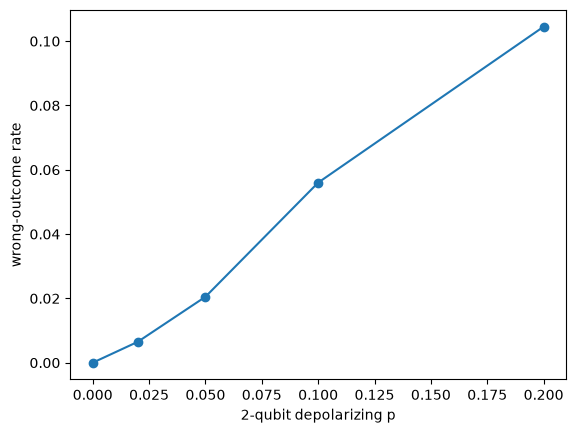

In [5]:
# Sweep the two-qubit error rate and plot how the wrong-outcome rate grows
import matplotlib.pyplot as plt
ps = [0, 0.02, 0.05, 0.1, 0.2]
errs = []
for p in ps:
    sim = AerSimulator(noise_model=make_noise(p2=p, pr=0.0))
    c = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    errs.append((c.get("01", 0) + c.get("10", 0)) / shots)
plt.plot(ps, errs, "o-"); plt.xlabel("2-qubit depolarizing p"); plt.ylabel("wrong-outcome rate"); plt.show()
assert errs[-1] > errs[0]